# Giai đoạn 5b: Mô hình Deep Learning — TextCNN (Multi-scale 1D CNN trên Word Embedding)

Huấn luyện và đánh giá **`TN5_textcnn` (`TextCNNClassifier`)** trên bộ dữ liệu đa nguồn **35 nhãn chuẩn** (`20.852` mẫu; `train=14.613`, `val=3.125`, `test=3.114`).

### Kiến trúc & tối ưu cho bài toán phân loại thể loại truyện:
1. **N-gram CNN đa tỷ lệ (`kernel_sizes = (2, 3, 4)`):** Các bộ lọc 1D Conv bắt trực tiếp cụm từ khóa 2–4 token đặc trưng thể loại.
2. **Khởi tạo Pretrained Embedding (`PPMI + TruncatedSVD`, `128` chiều) & Độ dài chuẩn `max_len = 750` (p99.9) + Dynamic Padding:** Học từ tập `train` (`vocab = 20.002`), bao phủ **99.91% truyện** (`99.76%` tổng token) để so sánh công bằng với BoW/TF-IDF, đồng thời dùng `LengthBucketBatchSampler` + Dynamic Padding theo batch giảm `<PAD>` từ `86.01%` xuống `23.80%`.
3. **Global Max + Masked Mean Pooling & Regularization:** Sử dụng `SpatialDropout(0.15)`, `BatchNorm1d`, `GELU`, `sqrt pos_weight (max=3.5)` và `OneCycleLR`.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch

from src.config import (
    EXPERIMENTS_CSV,
    FIGURES_DIR,
    GENRE_DISPLAY_NAMES,
    GENRE_LABELS,
    MODELS_DIR,
    RANDOM_STATE,
    STORIES_CLEAN_CSV,
    TEXTCNN_MAX_LEN,
)
from src.evaluation.metrics import (
    evaluate_model,
    plot_dl_learning_curves,
    plot_f1_per_label,
    plot_model_comparison,
    save_experiment_result,
)
from src.features.embedding import (
    build_corpus_embeddings,
    build_vocab,
    estimate_dynamic_pad_ratio,
    make_dynamic_dataloader,
    texts_to_id_lists,
)
from src.models.ml_models import apply_thresholds, tune_per_label_thresholds
from src.models.textcnn import (
    TextCNNClassifier,
    compute_pos_weights,
    predict_torch_probs,
    save_textcnn_checkpoint,
    train_torch_multilabel,
)

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    torch.set_num_threads(max(4, os.cpu_count() or 4))
print(f"PyTorch: {torch.__version__} | Thiết bị: {device} | CPU threads: {torch.get_num_threads()}")

df = pd.read_csv(STORIES_CLEAN_CSV, encoding="utf-8")
label_cols = [f"label_{g}" for g in GENRE_LABELS]
train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

y_train = train_df[label_cols].to_numpy(dtype=np.float32)
y_val = val_df[label_cols].to_numpy(dtype=np.float32)
y_test = test_df[label_cols].to_numpy(dtype=np.float32)

MAX_LEN = TEXTCNN_MAX_LEN
EMB_DIM = 128
BATCH_SIZE = 256

train_tokens = train_df["tokens"].fillna("")
val_tokens = val_df["tokens"].fillna("")
test_tokens = test_df["tokens"].fillna("")

vocab = build_vocab(train_tokens, min_freq=2, max_vocab_size=20000)
x_ids_train = texts_to_id_lists(train_tokens, vocab, max_len=MAX_LEN)
x_ids_val = texts_to_id_lists(val_tokens, vocab, max_len=MAX_LEN)
x_ids_eval = texts_to_id_lists(test_tokens, vocab, max_len=MAX_LEN)

t_emb = time.perf_counter()
pretrained_matrix = build_corpus_embeddings(
    train_tokens,
    vocab,
    embedding_dim=EMB_DIM,
    window=4,
    min_cooccur=2,
    n_iter=3,
    scale=0.5,
)
emb_time = time.perf_counter() - t_emb

pin_mem = device == "cuda"
seq_train_loader = make_dynamic_dataloader(
    x_ids_train,
    labels=y_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=pin_mem,
    seed=RANDOM_STATE,
)
seq_val_loader = make_dynamic_dataloader(
    x_ids_val,
    labels=y_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=pin_mem,
)
seq_test_loader = make_dynamic_dataloader(
    x_ids_eval,
    labels=y_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=pin_mem,
)

train_lens = np.array([len(s) for s in x_ids_train])
fixed_pad_pct = float((MAX_LEN - train_lens).mean() / MAX_LEN * 100.0)
dyn_pad_pct = estimate_dynamic_pad_ratio(x_ids_train, batch_size=BATCH_SIZE, bucketed=True, seed=RANDOM_STATE) * 100.0

pos_weight = compute_pos_weights(y_train, max_weight=3.5, mode="sqrt")
THRESH_GRID = np.round(np.linspace(0.15, 0.85, 71), 2)

print(f"Tập dữ liệu: train={len(train_df)}, val={len(val_df)}, test={len(test_df)}")
print(
    f"Vocab TextCNN (min_freq=2): {len(vocab)} | MAX_LEN={MAX_LEN} (Dynamic Padding batch={BATCH_SIZE}) | "
    f"PPMI-SVD Embedding: {pretrained_matrix.shape} ({emb_time:.2f}s)"
)
print(
    f"Tỷ lệ <PAD> trên train: Padding cố định={fixed_pad_pct:.2f}% -> Dynamic Padding (bucketed)={dyn_pad_pct:.2f}%"
)
print("pos_weight (sqrt, max=3.5):", {lbl: round(float(w), 2) for lbl, w in zip(GENRE_LABELS, pos_weight)})

PyTorch: 2.8.0+cpu | Thiết bị: cpu | CPU threads: 4


Tập dữ liệu: train=14613, val=3125, test=3114
Vocab TextCNN (min_freq=2): 20002 | MAX_LEN=750 (Dynamic Padding batch=256) | PPMI-SVD Embedding: (20002, 128) (3.33s)
Tỷ lệ <PAD> trên train: Padding cố định=86.01% -> Dynamic Padding (bucketed)=23.80%
pos_weight (sqrt, max=3.5): {'ngon_tinh': 1.16, 'dam_my': 2.06, 'bach_hop': 3.5, 'tong_tai': 3.5, 'nu_phu': 3.5, 'nu_cuong': 2.11, 'sung': 1.87, 'nguoc': 3.5, 'hai_huoc': 2.93, 'tien_hiep': 3.5, 'kiem_hiep': 3.5, 'huyen_huyen': 2.75, 'di_gioi': 3.5, 'di_nang': 3.5, 'mat_the': 3.5, 'khoa_huyen': 3.5, 'linh_di': 3.5, 'trinh_tham': 3.5, 'tham_hiem': 3.5, 'vong_du': 3.5, 'he_thong': 3.5, 'xuyen_khong': 2.46, 'trong_sinh': 2.75, 'co_dai': 1.56, 'hien_dai': 1.53, 'hoc_duong': 3.5, 'cung_dau': 3.5, 'gia_dau': 3.5, 'dien_van': 3.5, 'lich_su': 3.5, 'quan_su': 3.5, 'quan_truong': 3.5, 'doan_van': 3.5, 'tieu_thuyet': 3.5, 'khac': 2.47}


In [2]:
# Khảo sát định lượng chứng minh lựa chọn MAX_LEN = 750 (p99.9) & Dynamic Padding
from IPython.display import display
from sklearn.metrics import f1_score
from src.config import TFIDF_VECTORIZER_PATH
from src.features.bow_tfidf import load_tfidf_vectorizer
from src.models.ml_models import load_model, predict_probabilities

# 1. Thống kê phân vị độ dài tokens theo từng split và toàn tập
split_rows = []
for sp_name, sub_df in [("train", train_df), ("val", val_df), ("test", test_df), ("ALL", df)]:
    sp_lens = sub_df["tokens"].fillna("").astype(str).apply(lambda s: len(s.split())).to_numpy()
    split_rows.append(
        {
            "split": sp_name,
            "n_samples": len(sub_df),
            "p50": int(np.percentile(sp_lens, 50)),
            "p75": int(np.percentile(sp_lens, 75)),
            "p90": int(np.percentile(sp_lens, 90)),
            "p95": int(np.percentile(sp_lens, 95)),
            "p99": int(np.ceil(np.percentile(sp_lens, 99.0))),
            "p99_5": int(np.ceil(np.percentile(sp_lens, 99.5))),
            "p99_9": int(np.ceil(np.percentile(sp_lens, 99.9))),
            "max": int(sp_lens.max()),
            "cov_750_%": round(float((sp_lens <= TEXTCNN_MAX_LEN).mean() * 100), 2),
            "tok_750_%": round(float(np.minimum(sp_lens, TEXTCNN_MAX_LEN).sum() / sp_lens.sum() * 100), 2),
        }
    )
split_pct_df = pd.DataFrame(split_rows)
print("=== BẢNG 1: PHÂN VỊ ĐỘ DÀI TOKEN THEO SPLIT VÀ ĐỘ PHỦ TẠI MAX_LEN = 750 ===")
display(split_pct_df)

# 2. Đường cong độ phủ, tỷ lệ <PAD> và bão hòa thông tin (LogReg TF-IDF trên val)
all_lens = df["tokens"].fillna("").astype(str).apply(lambda s: len(s.split())).to_numpy()
total_all_tokens = int(all_lens.sum())

tfidf_vec = load_tfidf_vectorizer(TFIDF_VECTORIZER_PATH)
logreg_ref = load_model("logistic_regression", MODELS_DIR)
ml_thresh_map = json.loads((MODELS_DIR / "ml_thresholds.json").read_text(encoding="utf-8"))
logreg_thr = np.array([ml_thresh_map["logistic_regression"][g] for g in GENRE_LABELS], dtype=np.float32)
y_val_int_ref = y_val.astype(int)

cut_grid = [100, 150, 250, 300, 400, 500, 750, None]
cov_rows = []
for cut in cut_grid:
    m_eff = int(all_lens.max()) if cut is None else int(cut)
    doc_cov = float((all_lens <= m_eff).mean() * 100.0)
    n_trunc = int((all_lens > m_eff).sum())
    tok_cov = float(np.minimum(all_lens, m_eff).sum() / total_all_tokens * 100.0)
    fixed_pad = float((m_eff - np.minimum(all_lens, m_eff)).mean() / m_eff * 100.0)

    train_cut_ids = texts_to_id_lists(train_tokens, vocab, max_len=m_eff)
    dyn_pad = estimate_dynamic_pad_ratio(train_cut_ids, batch_size=BATCH_SIZE, bucketed=True, seed=RANDOM_STATE) * 100.0

    val_cut_toks = val_tokens if cut is None else val_tokens.apply(lambda s: " ".join(str(s).split()[:m_eff]))
    x_v_cut = tfidf_vec.transform(val_cut_toks)
    v_probs = predict_probabilities(logreg_ref, x_v_cut)
    v_preds = apply_thresholds(v_probs, thresholds=logreg_thr, ensure_non_empty=True)
    v_macro = float(f1_score(y_val_int_ref, v_preds, average="macro", zero_division=0))
    v_micro = float(f1_score(y_val_int_ref, v_preds, average="micro", zero_division=0))

    cov_rows.append(
        {
            "max_len": "FULL" if cut is None else int(cut),
            "docs_full_%": round(doc_cov, 2),
            "n_truncated": n_trunc,
            "tokens_kept_%": round(tok_cov, 2),
            "fixed_pad_%": round(fixed_pad, 2),
            "dynamic_pad_%": round(dyn_pad, 2),
            "logreg_val_macro_f1": round(v_macro, 4),
            "logreg_val_micro_f1": round(v_micro, 4),
        }
    )
cov_df = pd.DataFrame(cov_rows)
print("\n=== BẢNG 2: ĐỘ PHỦ DỮ LIỆU, TỶ LỆ <PAD> VÀ ĐỘ BÃO HÒA THÔNG TIN THEO MAX_LEN ===")
display(cov_df)

# 3. Tỷ lệ bị cắt cụt trên các thể loại có văn án dài nhất ở các mốc 300 / 400 / 500 / 750
trunc_rows = []
for g in GENRE_LABELS:
    sub_lens = all_lens[df[f"label_{g}"].to_numpy() == 1]
    trunc_rows.append(
        {
            "label": g,
            "ten_hien_thi": GENRE_DISPLAY_NAMES.get(g, g),
            "n_samples": int(len(sub_lens)),
            "p95": int(np.percentile(sub_lens, 95)),
            "p99": int(np.percentile(sub_lens, 99)),
            "trunc_300_%": round(float((sub_lens > 300).mean() * 100), 2),
            "trunc_400_%": round(float((sub_lens > 400).mean() * 100), 2),
            "trunc_500_%": round(float((sub_lens > 500).mean() * 100), 2),
            "trunc_750_%": round(float((sub_lens > TEXTCNN_MAX_LEN).mean() * 100), 2),
        }
    )
trunc_df = pd.DataFrame(trunc_rows).sort_values("trunc_300_%", ascending=False).head(8).reset_index(drop=True)
print("\n=== BẢNG 3: TỶ LỆ CẮT CỤT Ở CÁC THỂ LOẠI CÓ VĂN ÁN DÀI NHẤT ===")
display(trunc_df)

=== BẢNG 1: PHÂN VỊ ĐỘ DÀI TOKEN THEO SPLIT VÀ ĐỘ PHỦ TẠI MAX_LEN = 750 ===


,split,n_samples,p50,p75,p90,p95,p99,p99_5,p99_9,max,cov_750_%,tok_750_%
0,train,14613,81,126,203,269,432,494,690,1967,99.92,99.74
1,val,3125,84,131,204,279,413,476,647,1158,99.94,99.86
2,test,3114,82,127,209,266,405,487,845,1151,99.84,99.75
3,ALL,20852,82,127,204,270,424,494,700,1967,99.91,99.76



=== BẢNG 2: ĐỘ PHỦ DỮ LIỆU, TỶ LỆ <PAD> VÀ ĐỘ BÃO HÒA THÔNG TIN THEO MAX_LEN ===


,max_len,docs_full_%,n_truncated,tokens_kept_%,fixed_pad_%,dynamic_pad_%,logreg_val_macro_f1,logreg_val_micro_f1
0,100,62.68,7782,71.13,25.08,3.83,0.3940,0.5358
1,150,81.72,3811,83.69,41.23,5.14,0.3973,0.5407
2,250,93.84,1284,94.12,60.35,7.88,0.4068,0.5431
3,300,96.47,737,96.40,66.15,8.73,0.4108,0.5443
4,400,98.73,264,98.52,74.06,12.29,0.4114,0.5448
5,500,99.55,94,99.29,79.08,15.97,0.4117,0.5452
6,750,99.91,18,99.76,85.99,23.80,0.4116,0.5451
7,FULL,100.00,0,100.00,94.65,39.72,0.4115,0.5451



=== BẢNG 3: TỶ LỆ CẮT CỤT Ở CÁC THỂ LOẠI CÓ VĂN ÁN DÀI NHẤT ===


,label,ten_hien_thi,n_samples,p95,p99,trunc_300_%,trunc_400_%,trunc_500_%,trunc_750_%
0,bach_hop,Bách hợp,476,400,545,14.92,5.04,1.26,0.00
1,quan_su,Quân sự,246,369,591,9.76,4.47,2.85,0.81
2,khac,Khác,2950,366,510,9.56,3.39,1.15,0.20
3,dam_my,Đam mỹ,3988,336,474,7.12,2.46,0.70,0.05
4,lich_su,Lịch sử / Dã sử,477,332,542,6.29,3.35,1.47,0.21
5,sung,Sủng / Ngọt,4815,309,437,5.52,1.45,0.37,0.02
6,he_thong,Hệ thống,1080,308,450,5.37,1.76,0.46,0.09
7,xuyen_khong,Xuyên không / Xuyên nhanh,2962,303,444,5.10,1.69,0.51,0.07


### Cơ sở định lượng chọn `max_len = 750` (p99.9) & Dynamic Padding theo batch
- **Chuẩn bị dữ liệu & Embedding:** Nạp tập chia `14.613 / 3.125 / 3.114`, xây dựng từ điển `20.002` token (`min_freq=2`, tối đa `20.000`), khởi tạo ma trận Word Embedding `128` chiều bằng `PPMI + TruncatedSVD` trên `train` (`3.33s`) và tính `pos_weight` (`sqrt`, `max_weight=3.5`).
- **Tại sao chọn `max_len = 750`:**
  1. **Bao phủ ở ngưỡng p99.9 (`99.91%` truyện & `99.76%` token):** Toàn tập `20.852` truyện có `p99.9 = 700` token (`train: 690`, `val: 647`, `test: 845`). Mốc **`750`** giữ trọn **`99.91%`** văn bản, chỉ cắt `18` ngoại lệ siêu dài (`> 750` đến `1.967` token).
  2. **Công bằng tuyệt đối với BoW/TF-IDF:** Trên `val`, `Logistic Regression (TF-IDF)` tại mốc `750` đạt **`Macro-F1 = 0.4116`** (`Micro-F1 = 0.5451`), tương đương hoàn toàn mức đọc toàn văn (`FULL`: `0.4115` / `0.5451`), bảo toàn nguyên vẹn các nhãn dài như `bach_hop` (cắt `0.00%`), `dam_my` (`0.05%`), `sung` (`0.02%`), `xuyen_khong` (`0.07%`), `he_thong` (`0.09%`), `lich_su` (`0.21%`), `quan_su` (`0.81%`).
  3. **Tối ưu tốc độ bằng Dynamic Padding (`LengthBucketBatchSampler`):** Giảm tỷ lệ `<PAD>` trên tập `train` từ **`86.01%`** (padding cố định) xuống chỉ còn **`23.80%`**.

In [3]:
# Huấn luyện TN5: TextCNN (Multi-scale Conv1d + Global Max & Masked Mean Pooling)
NUM_FILTERS = 64
KERNEL_SIZES = (2, 3, 4)
DROPOUT = 0.35
SPATIAL_DROPOUT = 0.15

t0 = time.perf_counter()
textcnn_model = TextCNNClassifier(
    vocab_size=len(vocab),
    num_classes=len(GENRE_LABELS),
    embedding_dim=EMB_DIM,
    num_filters=NUM_FILTERS,
    kernel_sizes=KERNEL_SIZES,
    dropout=DROPOUT,
    pretrained_embeddings=pretrained_matrix,
    freeze_embeddings=False,
    spatial_dropout=SPATIAL_DROPOUT,
)
textcnn_model, cnn_history = train_torch_multilabel(
    textcnn_model,
    train_loader=seq_train_loader,
    val_loader=seq_val_loader,
    y_val=y_val.astype(int),
    epochs=10 if len(train_df) > 5000 else 20,
    lr=3e-3,
    weight_decay=1e-4,
    pos_weight=pos_weight,
    patience=4,
    device=device,
    use_scheduler=True,
    scheduler_type="onecycle",
    use_amp=True,
)
cnn_train_s = time.perf_counter() - t0

cnn_val_probs = predict_torch_probs(textcnn_model, seq_val_loader, device=device)
cnn_val_default = evaluate_model(
    y_val.astype(int),
    apply_thresholds(cnn_val_probs, 0.5),
    label_names=GENRE_LABELS,
)
cnn_opt_thresh = tune_per_label_thresholds(y_val.astype(int), cnn_val_probs, grid=THRESH_GRID)
cnn_val_tuned = evaluate_model(
    y_val.astype(int),
    apply_thresholds(cnn_val_probs, cnn_opt_thresh),
    label_names=GENRE_LABELS,
)

use_tuned = cnn_val_tuned["macro_f1"] >= cnn_val_default["macro_f1"]
chosen_thresh = cnn_opt_thresh if use_tuned else np.full(len(GENRE_LABELS), 0.5, dtype=np.float32)

save_textcnn_checkpoint(
    textcnn_model,
    vocab=vocab,
    max_len=MAX_LEN,
    thresholds=chosen_thresh,
    path=MODELS_DIR / "textcnn.pt",
)

print(f"[TN5 TextCNN] Thời gian train: {cnn_train_s:.2f}s | Số epoch đã chạy: {len(cnn_history['train_loss'])}")
print(
    f"  Val (ngưỡng 0.5)    : Accuracy={cnn_val_default['accuracy']}, "
    f"Macro-F1={cnn_val_default['macro_f1']}, Micro-F1={cnn_val_default['micro_f1']}, Hamming={cnn_val_default['hamming_loss']}"
)
print(
    f"  Val (ngưỡng tối ưu) : Accuracy={cnn_val_tuned['accuracy']}, "
    f"Macro-F1={cnn_val_tuned['macro_f1']}, Micro-F1={cnn_val_tuned['micro_f1']}, Hamming={cnn_val_tuned['hamming_loss']}"
)
display(pd.DataFrame(cnn_history).assign(epoch=lambda d: np.arange(1, len(d) + 1)))

[TN5 TextCNN] Thời gian train: 294.54s | Số epoch đã chạy: 10
  Val (ngưỡng 0.5)    : Accuracy=0.0445, Macro-F1=0.3315, Micro-F1=0.5063, Hamming=0.0887
  Val (ngưỡng tối ưu) : Accuracy=0.024, Macro-F1=0.3795, Micro-F1=0.5067, Hamming=0.1214


,train_loss,val_loss,val_macro_f1,val_micro_f1,epoch
0,0.6642,0.5073,0.0691,0.3220,1
1,0.4188,0.3923,0.1985,0.4671,2
2,0.3683,0.3760,0.2618,0.4901,3
3,0.3352,0.3591,0.2660,0.5029,4
4,0.3108,0.3610,0.2963,0.5116,5
5,0.2881,0.3627,0.3234,0.5133,6
6,0.2688,0.3679,0.3286,0.5097,7
7,0.2553,0.3733,0.3307,0.5062,8
8,0.2466,0.3732,0.3315,0.5063,9
9,0.2434,0.3740,0.3304,0.5051,10


### Phân tích quá trình huấn luyện `TN5_textcnn`
- Thời gian huấn luyện `10 epochs` trên CPU là **`294.54s`**: `val_loss` giảm nhanh từ `0.5073` (epoch 1) xuống đáy `0.3591` (epoch 4), trong khi `val Macro-F1` tăng đều đến đỉnh **`0.3315`** (`val Micro-F1 = 0.5063`) tại epoch 9.
- Tối ưu ngưỡng 71 điểm (`0.15`–`0.85`) trên tập `val` giúp `Macro-F1` của `TextCNN` tăng mạnh từ **`0.3315 -> 0.3795`** (`Micro-F1 = 0.5067`).

In [4]:
# Đánh giá cuối cùng trên tập TEST (chạy duy nhất 1 lần) & cập nhật experiments.csv
if EXPERIMENTS_CSV.exists() and EXPERIMENTS_CSV.stat().st_size > 0:
    exp_existing = pd.read_csv(EXPERIMENTS_CSV, encoding="utf-8")
    if "experiment_id" in exp_existing.columns:
        valid_exp_ids = [
            "TN1_nb_bow",
            "TN2_multinomial_nb",
            "TN3_linear_svm",
            "TN4_logistic_regression",
            "TN5_textcnn",
        ]
        exp_existing = exp_existing[exp_existing["experiment_id"].isin(valid_exp_ids)]
        exp_existing.to_csv(EXPERIMENTS_CSV, index=False, encoding="utf-8")

t0 = time.perf_counter()
te_probs = predict_torch_probs(textcnn_model, seq_test_loader, device=device)
infer_ms = (time.perf_counter() - t0) * 1000.0

thresh_mode = "tuned_thresholds" if use_tuned else "threshold=0.5"
te_preds = apply_thresholds(te_probs, thresholds=chosen_thresh, ensure_non_empty=True)
te_metrics = evaluate_model(y_test.astype(int), te_preds, label_names=GENRE_LABELS)

dl_thresholds_json = {
    "TN5_textcnn": {lbl: round(float(chosen_thresh[i]), 2) for i, lbl in enumerate(GENRE_LABELS)}
}
(MODELS_DIR / "dl_thresholds.json").write_text(
    json.dumps(dl_thresholds_json, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

save_experiment_result(
    experiment_id="TN5_textcnn",
    model_name="TextCNN (Word Embedding)",
    feature_type=f"PPMI-SVD Emb + Multi-scale CNN (max_len={MAX_LEN})",
    metrics=te_metrics,
    notes=f"Test set ({len(y_test)} mẫu) | TextCNN (k=2,3,4; f={NUM_FILTERS}; emb={EMB_DIM} PPMI-SVD; dynamic_pad) + sqrt pos_weight | {thresh_mode}",
    output_path=EXPERIMENTS_CSV,
)

all_exp_df = pd.read_csv(EXPERIMENTS_CSV, encoding="utf-8")
print("=== BẢNG TỔNG HỢP TOÀN BỘ 5 THÍ NGHIỆM (ML vs TEXTCNN) TRÊN TẬP TEST ===")
display(all_exp_df)

print(
    f"\nMô hình Deep Learning TextCNN: Accuracy={te_metrics['accuracy']}, "
    f"Macro-F1={te_metrics['macro_f1']}, Micro-F1={te_metrics['micro_f1']}, "
    f"Hamming={te_metrics['hamming_loss']}, infer={infer_ms:.2f} ms"
)

dl_per_label_rows = []
for lbl in GENRE_LABELS:
    row = te_metrics["per_label"][lbl]
    dl_per_label_rows.append(
        {
            "label": lbl,
            "ten_hien_thi": GENRE_DISPLAY_NAMES.get(lbl, lbl),
            "precision": round(row["precision"], 4),
            "recall": round(row["recall"], 4),
            "f1_score": round(row["f1-score"], 4),
            "support": int(row["support"]),
        }
    )
dl_per_label_df = pd.DataFrame(dl_per_label_rows).sort_values("f1_score", ascending=False).reset_index(drop=True)
display(dl_per_label_df)

=== BẢNG TỔNG HỢP TOÀN BỘ 5 THÍ NGHIỆM (ML vs TEXTCNN) TRÊN TẬP TEST ===


,experiment_id,model_name,feature_type,accuracy,macro_f1,micro_f1,hamming_loss,notes
0,TN1_nb_bow,Multinomial NB (BoW),BoW (1-2 gram),0.0193,0.3501,0.4889,0.1186,Test set (3114 mẫu) | alpha=0.25 | tuned_thres...
1,TN2_multinomial_nb,Multinomial NB (TF-IDF),TF-IDF (1-2 gram),0.0286,0.3347,0.5376,0.0947,Test set (3114 mẫu) | alpha=0.05 | tuned_thres...
2,TN3_linear_svm,Linear SVM (TF-IDF),TF-IDF (1-2 gram),0.0260,0.3868,0.5276,0.1041,"Test set (3114 mẫu) | C=0.25, cw=balanced | tu..."
3,TN4_logistic_regression,Logistic Regression (TF-IDF),TF-IDF (1-2 gram),0.0302,0.3944,0.5413,0.1008,"Test set (3114 mẫu) | C=2.0, cw=balanced | tun..."
4,TN5_textcnn,TextCNN (Word Embedding),PPMI-SVD Emb + Multi-scale CNN (max_len=750),0.0218,0.3503,0.4968,0.1255,"Test set (3114 mẫu) | TextCNN (k=2,3,4; f=64; ..."



Mô hình Deep Learning TextCNN: Accuracy=0.0218, Macro-F1=0.3503, Micro-F1=0.4968, Hamming=0.1255, infer=5803.76 ms


,label,ten_hien_thi,precision,recall,f1_score,support
0,ngon_tinh,Ngôn tình (Nam–Nữ),0.7428,0.9279,0.8251,1721
1,co_dai,Cổ đại,0.8035,0.7991,0.8013,911
2,dam_my,Đam mỹ,0.7996,0.7609,0.7798,598
3,hien_dai,Hiện đại / Đô thị,0.5236,0.8507,0.6483,938
4,tien_hiep,Tiên hiệp,0.5373,0.6462,0.5867,212
5,xuyen_khong,Xuyên không / Xuyên nhanh,0.4533,0.5775,0.5079,445
6,nu_cuong,Nữ cường,0.3789,0.7321,0.4994,545
7,huyen_huyen,Huyền huyễn,0.3961,0.6110,0.4806,365
8,sung,Sủng / Ngọt,0.3291,0.8729,0.4780,779
9,kiem_hiep,Kiếm hiệp,0.4247,0.5000,0.4593,62


### Phân tích so sánh TextCNN vs ML Baselines trên tập Test (`3.114` mẫu)
- Trên `3.114` mẫu Test (`35` nhãn), **`TN5_textcnn`** đạt **`Macro-F1 = 0.3503`**, **`Micro-F1 = 0.4968`**, **`Accuracy = 0.0218`**, **`Hamming Loss = 0.1255`** (`infer = 5803.76 ms`), vượt `TN1_nb_bow` (`0.3501`) và `TN2_multinomial_nb` (`0.3347`) về Macro-F1.
- Nhóm nhãn dẫn đầu trên `TextCNN` gồm `ngon_tinh` (`0.8251` — cao nhất toàn bộ mô hình), `co_dai` (`0.8013`), `dam_my` (`0.7798`), `hien_dai` (`0.6483`), `tien_hiep` (`0.5867`), `xuyen_khong` (`0.5079`), `nu_cuong` (`0.4994`), `huyen_huyen` (`0.4806`). Với bài toán `35` nhãn gồm nhiều nhãn hiếm ít mẫu, mô hình tuyến tính thưa `TF-IDF + Logistic Regression` (`Macro-F1 = 0.3944`, `Micro-F1 = 0.5413`) vẫn hiệu quả hơn mạng CNN học từ vựng từ đầu.

Đã lưu biểu đồ: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\figures\dl_learning_curves.png


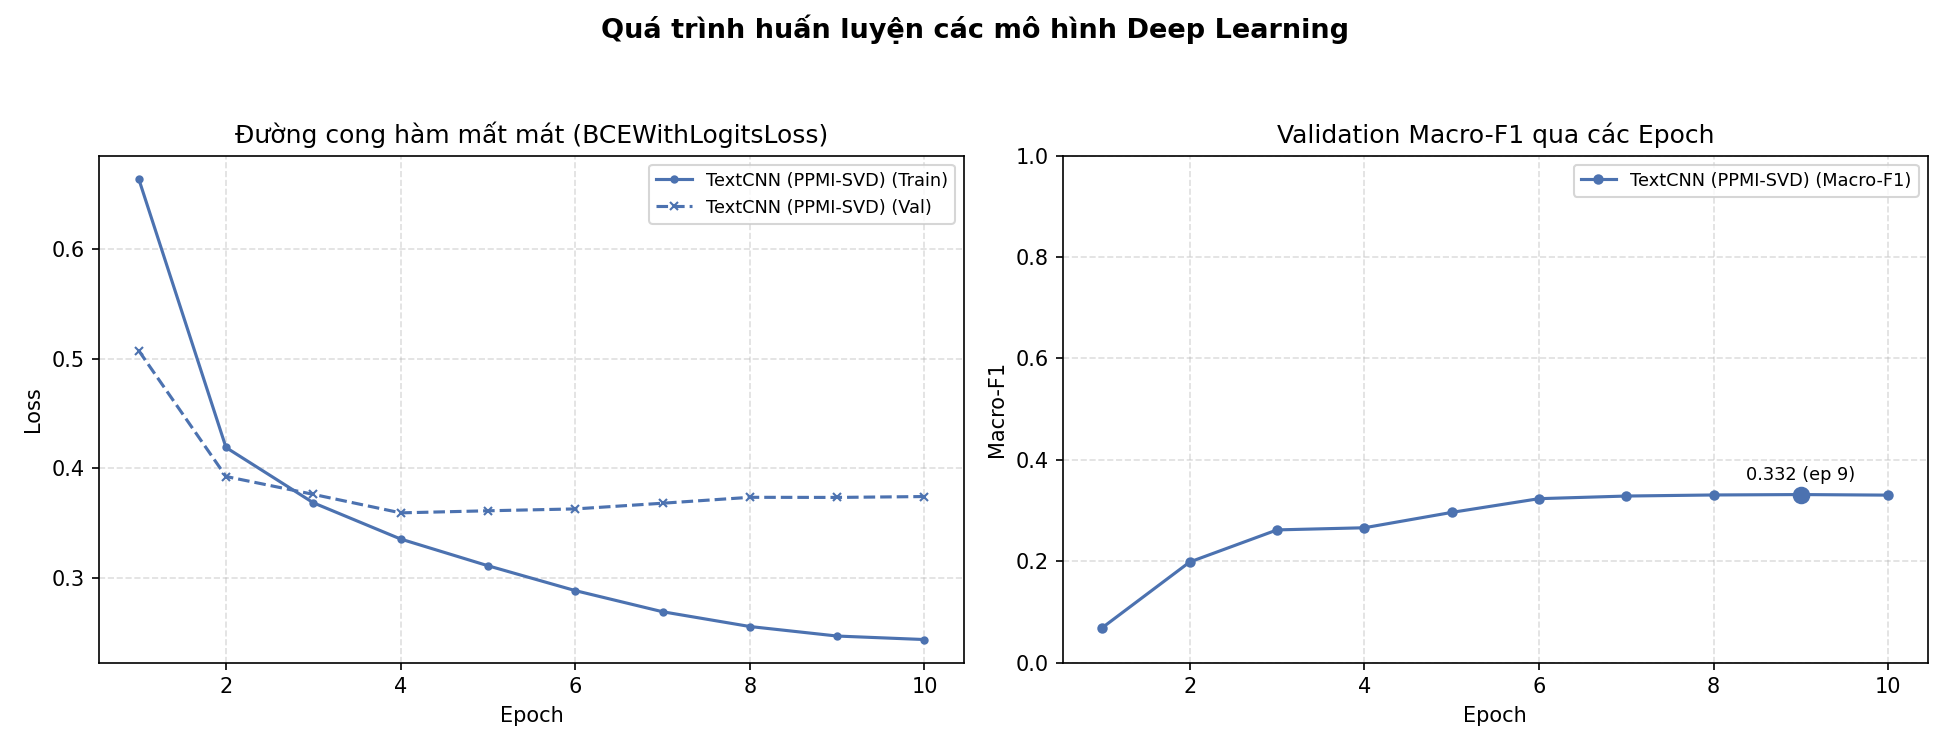

Đã lưu biểu đồ: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\figures\all_models_comparison.png


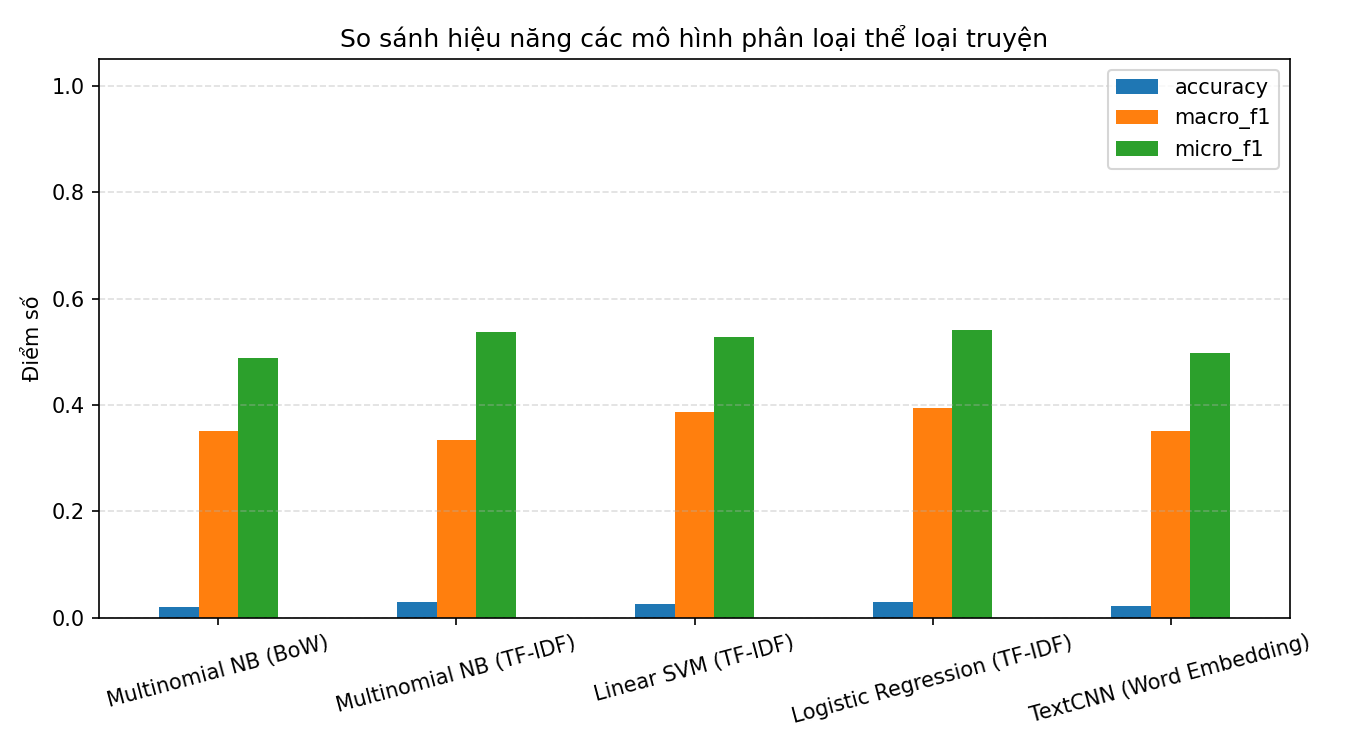

Đã lưu biểu đồ: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\figures\dl_f1_per_label.png


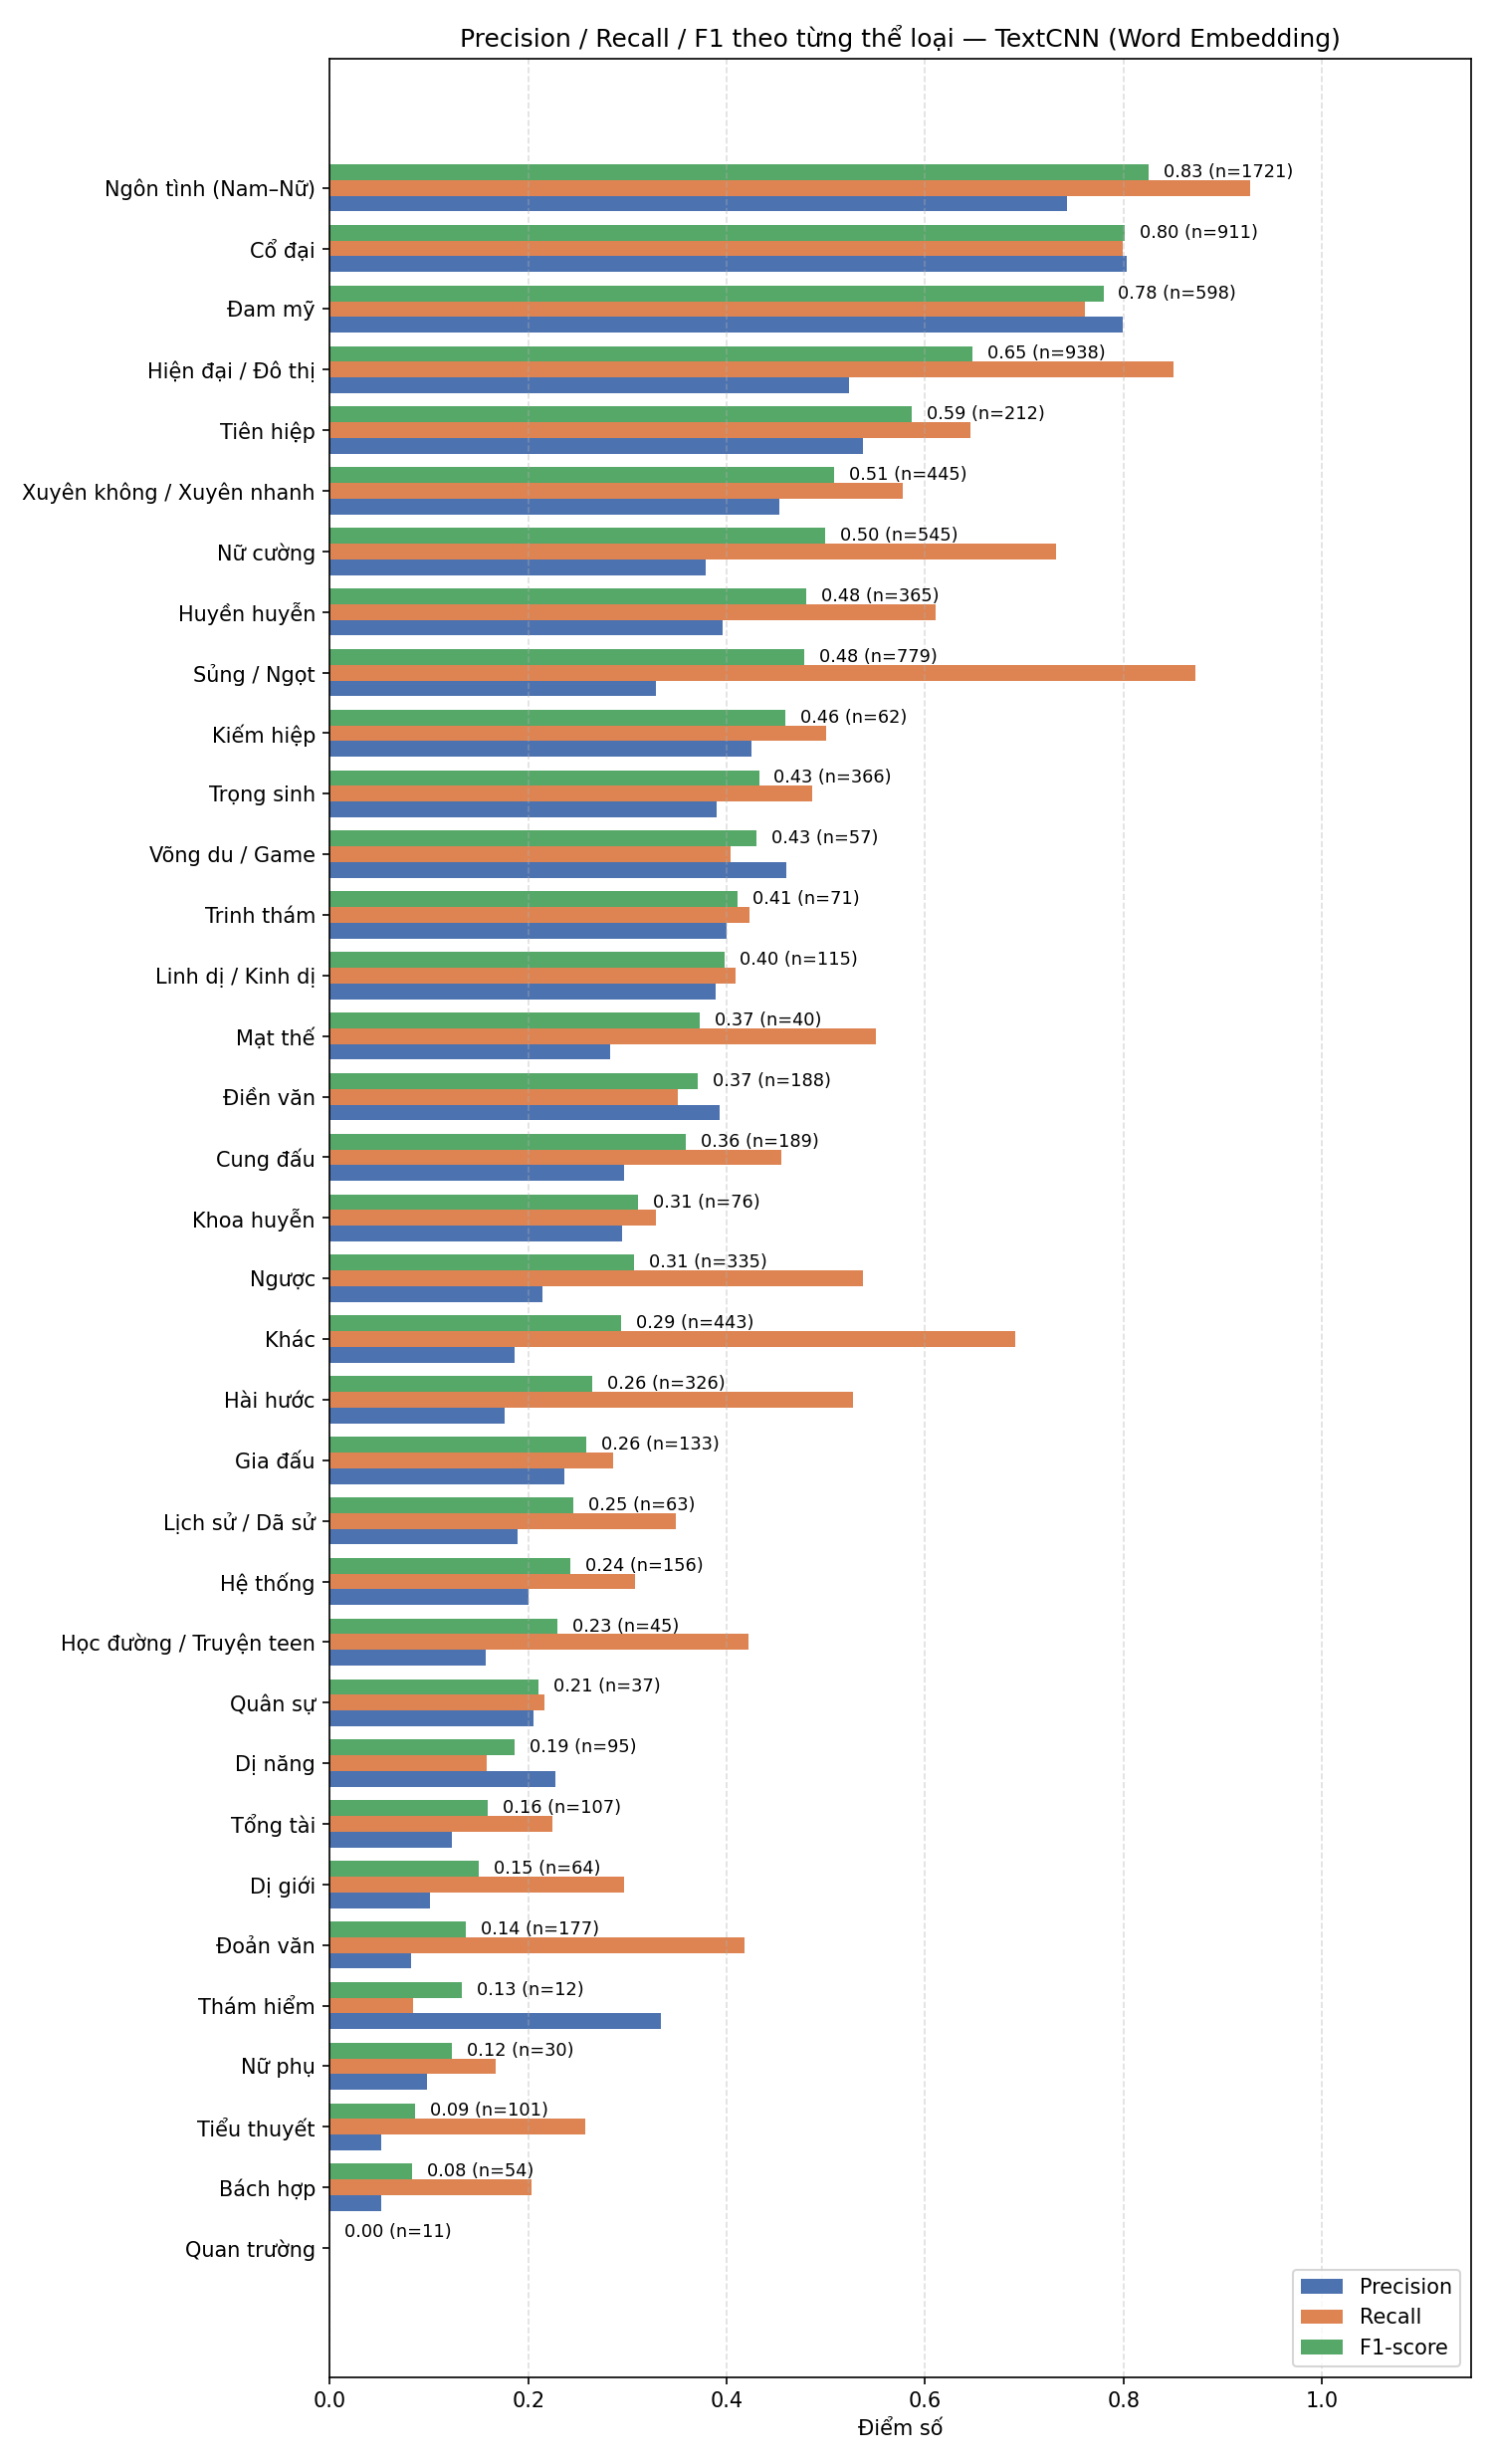

In [5]:
# Vẽ và lưu 3 biểu đồ chuẩn vào outputs/figures/
from IPython.display import Image, display

fig_lc = plot_dl_learning_curves(
    {"TextCNN (PPMI-SVD)": cnn_history},
    output_path=FIGURES_DIR / "dl_learning_curves.png",
)
fig_all = plot_model_comparison(
    all_exp_df,
    output_path=FIGURES_DIR / "all_models_comparison.png",
)
fig_dl_f1 = plot_f1_per_label(
    te_metrics["per_label"],
    label_names=GENRE_LABELS,
    model_name="TextCNN (Word Embedding)",
    output_path=FIGURES_DIR / "dl_f1_per_label.png",
)

for p in [fig_lc, fig_all, fig_dl_f1]:
    if p is not None and p.exists():
        print("Đã lưu biểu đồ:", p)
        display(Image(filename=str(p)))

### Biểu đồ trực quan Learning Curves, So sánh 5 thí nghiệm & F1 theo 35 nhãn
- Xuất 3 biểu đồ chuẩn: `dl_learning_curves.png`, `all_models_comparison.png`, `dl_f1_per_label.png`.

In [6]:
# Kiểm định độ tin cậy thống kê (Bootstrap 95% CI, 1.000 lần): Logistic Regression vs Linear SVM vs TextCNN
from sklearn.metrics import f1_score
from src.config import TABLES_DIR, TFIDF_VECTORIZER_PATH
from src.features.bow_tfidf import load_tfidf_vectorizer
from src.models.ml_models import apply_thresholds, load_model, predict_probabilities
from src.models.textcnn import load_textcnn_checkpoint, predict_torch_probs

exp_df = pd.read_csv(EXPERIMENTS_CSV, encoding="utf-8")
tfidf_vec = load_tfidf_vectorizer(TFIDF_VECTORIZER_PATH)
x_test_tfidf = tfidf_vec.transform(test_tokens)

ml_thresh_map = json.loads((MODELS_DIR / "ml_thresholds.json").read_text(encoding="utf-8"))
dl_thresh_map = json.loads((MODELS_DIR / "dl_thresholds.json").read_text(encoding="utf-8"))

logreg_model = load_model("logistic_regression", MODELS_DIR)
svm_model = load_model("linear_svm", MODELS_DIR)
textcnn_eval_bundle = load_textcnn_checkpoint(MODELS_DIR / "textcnn.pt", device="cpu")
textcnn_eval_model = textcnn_eval_bundle["model"]
x_ids_val_eval = texts_to_id_lists(val_tokens, textcnn_eval_bundle["vocab"], max_len=textcnn_eval_bundle["max_len"])
x_ids_test_eval = texts_to_id_lists(test_tokens, textcnn_eval_bundle["vocab"], max_len=textcnn_eval_bundle["max_len"])
seq_test_eval_loader = make_dynamic_dataloader(x_ids_test_eval, labels=None, batch_size=256, shuffle=False)

logreg_thresh = np.array([ml_thresh_map["logistic_regression"][g] for g in GENRE_LABELS], dtype=np.float32)
svm_thresh = np.array([ml_thresh_map["linear_svm"][g] for g in GENRE_LABELS], dtype=np.float32)
textcnn_thresh = np.array([dl_thresh_map["TN5_textcnn"][g] for g in GENRE_LABELS], dtype=np.float32)

probs_dict = {
    "Logistic Regression": predict_probabilities(logreg_model, x_test_tfidf),
    "Linear SVM": predict_probabilities(svm_model, x_test_tfidf),
    "TextCNN (Word Embedding)": predict_torch_probs(
        textcnn_eval_model,
        seq_test_eval_loader,
    ),
}
preds_dict = {
    "Logistic Regression": apply_thresholds(probs_dict["Logistic Regression"], logreg_thresh),
    "Linear SVM": apply_thresholds(probs_dict["Linear SVM"], svm_thresh),
    "TextCNN (Word Embedding)": apply_thresholds(probs_dict["TextCNN (Word Embedding)"], textcnn_thresh),
}

y_val_int = y_val.astype(int)
y_test_int = y_test.astype(int)

rng = np.random.default_rng(RANDOM_STATE)
n_boot = 1000
n_test = len(y_test_int)
boot_idx = rng.integers(0, n_test, size=(n_boot, n_test))

boot_rows = []
boot_samples = {}
for name, y_pred in preds_dict.items():
    macros = np.empty(n_boot, dtype=np.float64)
    micros = np.empty(n_boot, dtype=np.float64)
    for b in range(n_boot):
        idx = boot_idx[b]
        macros[b] = f1_score(y_test_int[idx], y_pred[idx], average="macro", zero_division=0)
        micros[b] = f1_score(y_test_int[idx], y_pred[idx], average="micro", zero_division=0)
    boot_samples[name] = {"macro": macros, "micro": micros}
    point = evaluate_model(y_test_int, y_pred, GENRE_LABELS)
    boot_rows.append(
        {
            "model": name,
            "macro_f1": point["macro_f1"],
            "macro_ci_95": f"[{np.percentile(macros, 2.5):.4f}, {np.percentile(macros, 97.5):.4f}]",
            "micro_f1": point["micro_f1"],
            "micro_ci_95": f"[{np.percentile(micros, 2.5):.4f}, {np.percentile(micros, 97.5):.4f}]",
            "hamming_loss": point["hamming_loss"],
        }
    )

diff_lr_svm = boot_samples["Logistic Regression"]["macro"] - boot_samples["Linear SVM"]["macro"]
diff_lr_cnn = boot_samples["Logistic Regression"]["macro"] - boot_samples["TextCNN (Word Embedding)"]["macro"]
print(f"Chênh lệch Macro-F1 (LogReg - SVM) 95% CI: [{np.percentile(diff_lr_svm, 2.5):+.4f}, {np.percentile(diff_lr_svm, 97.5):+.4f}]")
print(f"Chênh lệch Macro-F1 (LogReg - TextCNN) 95% CI: [{np.percentile(diff_lr_cnn, 2.5):+.4f}, {np.percentile(diff_lr_cnn, 97.5):+.4f}]")
display(exp_df)
display(pd.DataFrame(boot_rows))

Chênh lệch Macro-F1 (LogReg - SVM) 95% CI: [-0.0012, +0.0162]
Chênh lệch Macro-F1 (LogReg - TextCNN) 95% CI: [+0.0267, +0.0611]


,experiment_id,model_name,feature_type,accuracy,macro_f1,micro_f1,hamming_loss,notes
0,TN1_nb_bow,Multinomial NB (BoW),BoW (1-2 gram),0.0193,0.3501,0.4889,0.1186,Test set (3114 mẫu) | alpha=0.25 | tuned_thres...
1,TN2_multinomial_nb,Multinomial NB (TF-IDF),TF-IDF (1-2 gram),0.0286,0.3347,0.5376,0.0947,Test set (3114 mẫu) | alpha=0.05 | tuned_thres...
2,TN3_linear_svm,Linear SVM (TF-IDF),TF-IDF (1-2 gram),0.0260,0.3868,0.5276,0.1041,"Test set (3114 mẫu) | C=0.25, cw=balanced | tu..."
3,TN4_logistic_regression,Logistic Regression (TF-IDF),TF-IDF (1-2 gram),0.0302,0.3944,0.5413,0.1008,"Test set (3114 mẫu) | C=2.0, cw=balanced | tun..."
4,TN5_textcnn,TextCNN (Word Embedding),PPMI-SVD Emb + Multi-scale CNN (max_len=750),0.0218,0.3503,0.4968,0.1255,"Test set (3114 mẫu) | TextCNN (k=2,3,4; f=64; ..."


,model,macro_f1,macro_ci_95,micro_f1,micro_ci_95,hamming_loss
0,Logistic Regression,0.3944,"[0.3786, 0.4067]",0.5413,"[0.5337, 0.5495]",0.1008
1,Linear SVM,0.3868,"[0.3699, 0.4009]",0.5276,"[0.5196, 0.5355]",0.1041
2,TextCNN (Word Embedding),0.3503,"[0.3376, 0.3644]",0.4968,"[0.4895, 0.5045]",0.1255


### Phân tích độ tin cậy thống kê (Bootstrap 95% CI)
- Với **`1.000` lần Bootstrap trên `3.114` mẫu Test**:
  - `Logistic Regression (TF-IDF)`: `Macro-F1 = 0.3944 [0.3786, 0.4067]`, `Micro-F1 = 0.5413 [0.5337, 0.5495]`.
  - `Linear SVM (TF-IDF)`: `Macro-F1 = 0.3868 [0.3699, 0.4009]`, `Micro-F1 = 0.5276 [0.5196, 0.5355]`.
  - `TextCNN (Word Embedding)`: `Macro-F1 = 0.3503 [0.3376, 0.3644]`, `Micro-F1 = 0.4968 [0.4895, 0.5045]`.
- Hiệu số `LogReg - TextCNN` có 95% CI **`[+0.0267, +0.0611]`** (dương hoàn toàn, có ý nghĩa thống kê ở mức 95%), còn hiệu số `LogReg - SVM` đạt **`[-0.0012, +0.0162]`** (nghiêng rõ về `LogReg`).

Đã lưu bảng phân tích theo phân khúc tại: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\tables\error_analysis_by_slice.csv


,dimension,slice,n_samples,avg_labels,logreg_micro_f1,logreg_macro_f1,logreg_exact_acc,svm_micro_f1,svm_macro_f1,svm_exact_acc,textcnn_micro_f1,textcnn_macro_f1,textcnn_exact_acc
0,header_bucket,Có header Thể loại,779,3.24,0.5626,0.4004,0.0372,0.5458,0.3962,0.0308,0.5080,0.3403,0.0218
1,header_bucket,Không có header,2335,3.14,0.5343,0.3837,0.0278,0.5216,0.3736,0.0244,0.4930,0.3426,0.0218
2,length_bucket,<100 từ,723,2.83,0.4843,0.3561,0.0166,0.4661,0.3476,0.0180,0.4611,0.3042,0.0249
3,length_bucket,100-250 từ,1642,3.21,0.5390,0.3779,0.0280,0.5256,0.3667,0.0231,0.4987,0.3544,0.0250
4,length_bucket,>250 từ,749,3.41,0.5934,0.4217,0.0481,0.5837,0.4135,0.0401,0.5183,0.3605,0.0120
5,n_labels_bucket,1 nhãn,502,1.00,0.2938,0.1944,0.0239,0.2850,0.1992,0.0279,0.2339,0.1706,0.0159
6,n_labels_bucket,2 nhãn,618,2.00,0.4623,0.2974,0.0259,0.4422,0.2950,0.0194,0.4008,0.2596,0.0275
7,n_labels_bucket,3 nhãn,853,3.00,0.5700,0.3970,0.0422,0.5566,0.3795,0.0387,0.5136,0.3234,0.0234
8,n_labels_bucket,>=4 nhãn,1141,4.88,0.6032,0.4211,0.0263,0.5887,0.4100,0.0193,0.5746,0.3843,0.0202


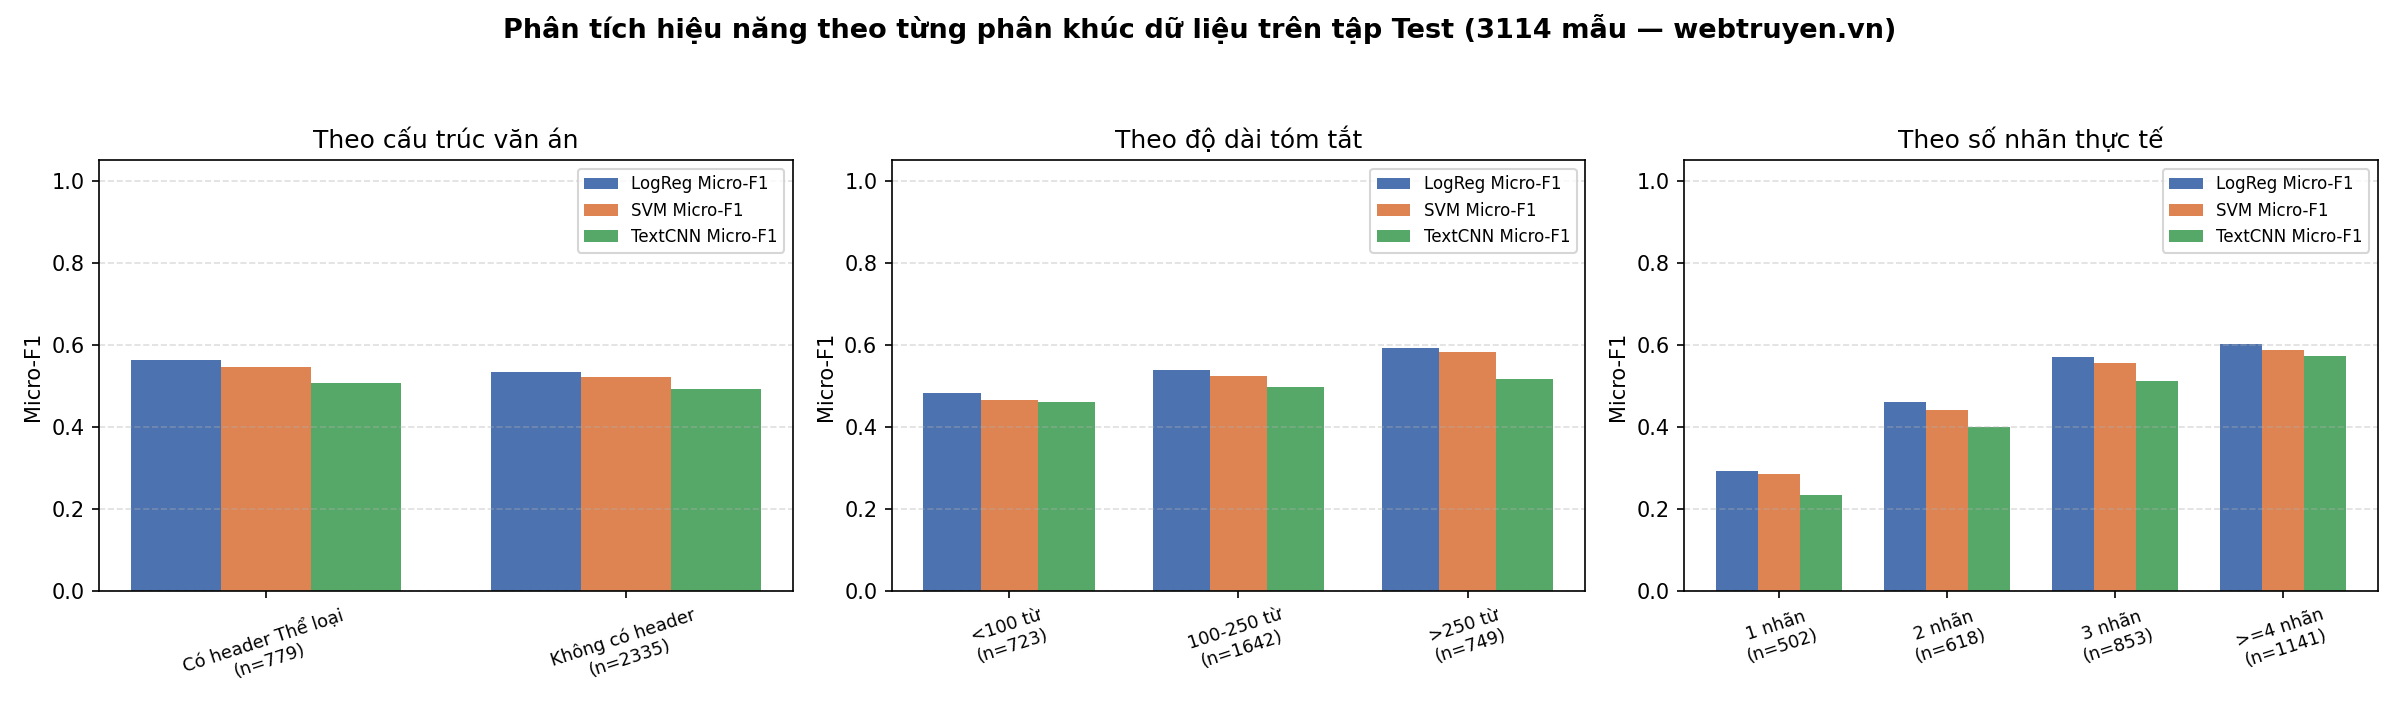

In [7]:
# Slice-based Error Analysis theo cấu trúc văn án, độ dài tóm tắt và số nhãn thực tế
import matplotlib.pyplot as plt

test_eval = test_df.copy()
test_eval["length_bucket"] = pd.cut(
    test_eval["n_words"],
    bins=[0, 100, 250, 100000],
    labels=["<100 từ", "100-250 từ", ">250 từ"],
)
test_eval["header_bucket"] = test_eval["summary"].fillna("").str.contains(
    r"thể\s*loại\s*[:\-]", case=False, regex=True
).map({True: "Có header Thể loại", False: "Không có header"})
test_eval["n_labels_bucket"] = test_eval["n_labels"].apply(lambda k: ">=4 nhãn" if k >= 4 else f"{int(k)} nhãn")

def _slice_metrics(group_col: str, ordered_keys=None) -> pd.DataFrame:
    rows = []
    keys = ordered_keys if ordered_keys is not None else sorted(test_eval[group_col].astype(str).unique())
    for key in keys:
        mask = (test_eval[group_col].astype(str) == key).to_numpy()
        if mask.sum() == 0:
            continue
        yt = y_test_int[mask]
        row = {"dimension": group_col, "slice": key, "n_samples": int(mask.sum()), "avg_labels": round(float(yt.sum(axis=1).mean()), 2)}
        for m_key, m_col in [("Logistic Regression", "logreg"), ("Linear SVM", "svm"), ("TextCNN (Word Embedding)", "textcnn")]:
            yp = preds_dict[m_key][mask]
            present = (yt.sum(axis=0) + yp.sum(axis=0)) > 0
            macro_present = float(f1_score(yt[:, present], yp[:, present], average="macro", zero_division=0)) if present.any() else 0.0
            micro = float(f1_score(yt, yp, average="micro", zero_division=0))
            acc = float((yt == yp).all(axis=1).mean())
            row[f"{m_col}_micro_f1"] = round(micro, 4)
            row[f"{m_col}_macro_f1"] = round(macro_present, 4)
            row[f"{m_col}_exact_acc"] = round(acc, 4)
        rows.append(row)
    return pd.DataFrame(rows)

slice_df = pd.concat([
    _slice_metrics("header_bucket", ["Có header Thể loại", "Không có header"]),
    _slice_metrics("length_bucket", ["<100 từ", "100-250 từ", ">250 từ"]),
    _slice_metrics("n_labels_bucket", ["1 nhãn", "2 nhãn", "3 nhãn", ">=4 nhãn"]),
], ignore_index=True)

slice_csv_path = TABLES_DIR / "error_analysis_by_slice.csv"
slice_df.to_csv(slice_csv_path, index=False, encoding="utf-8")
print(f"Đã lưu bảng phân tích theo phân khúc tại: {slice_csv_path}")
display(slice_df)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
dims = [("header_bucket", "Theo cấu trúc văn án"), ("length_bucket", "Theo độ dài tóm tắt"), ("n_labels_bucket", "Theo số nhãn thực tế")]
for ax, (dim_name, title) in zip(axes, dims):
    sub = slice_df[slice_df["dimension"] == dim_name]
    x = np.arange(len(sub))
    w = 0.25
    ax.bar(x - w, sub["logreg_micro_f1"], width=w, label="LogReg Micro-F1", color="#4c72b0")
    ax.bar(x, sub["svm_micro_f1"], width=w, label="SVM Micro-F1", color="#dd8452")
    ax.bar(x + w, sub["textcnn_micro_f1"], width=w, label="TextCNN Micro-F1", color="#55a868")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{s}\n(n={n})" for s, n in zip(sub["slice"], sub["n_samples"])], rotation=18, fontsize=8.5)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Micro-F1")
    ax.set_title(title)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(fontsize=8)

fig.suptitle(f"Phân tích hiệu năng theo từng phân khúc dữ liệu trên tập Test ({len(y_test_int)} mẫu — webtruyen.vn)", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
slice_fig_path = FIGURES_DIR / "error_analysis_slices.png"
plt.savefig(slice_fig_path, dpi=150)
plt.close(fig)
display(Image(filename=str(slice_fig_path)))

### Phân tích lỗi theo phân khúc dữ liệu (`3.114` mẫu Test)
- **Theo cấu trúc header:** Nhóm `"Có header Thể loại"` (`n=779`) đạt kết quả cao hơn `"Không có header"` (`n=2.335`) trên cả `LogReg` (`Micro-F1 = 0.5626 / Macro-F1 = 0.4004` vs `0.5343 / 0.3837`) và `SVM` (`0.5458` vs `0.5216`).
- **Theo độ dài văn án:** Truyện dài `>250 từ` (`n=749`) đạt hiệu năng cao nhất trên cả 3 mô hình (`LogReg Micro-F1 = 0.5934 / Macro-F1 = 0.4217`, `SVM = 0.5837 / 0.4135`, `TextCNN = 0.5183 / 0.3605`), vượt xa nhóm ngắn `<100 từ` (`n=723`, `LogReg Micro-F1 = 0.4843`).
- **Theo số nhãn thực tế:** Truyện `3 nhãn` (`n=853`) đạt `Exact Acc` cao nhất (`LogReg = 4.22%`, `SVM = 3.87%`), còn truyện `>=4 nhãn` (`n=1.141`, `avg_labels = 4.88`) đạt `Micro-F1` cao nhất (`LogReg = 0.6032`, `SVM = 0.5887`, `TextCNN = 0.5746`).

In [8]:
# Phân nhóm lỗi thừa/thiếu nhãn giữa 3 mô hình & Khảo sát độ nhạy ngưỡng trên nhãn trong_sinh của TextCNN
err_type_rows = []
for name, y_pred in preds_dict.items():
    exact = int(((y_test_int == y_pred).all(axis=1)).sum())
    fp_cnt = ((y_pred == 1) & (y_test_int == 0)).sum(axis=1)
    fn_cnt = ((y_pred == 0) & (y_test_int == 1)).sum(axis=1)
    overlap = ((y_pred == 1) & (y_test_int == 1)).sum(axis=1)

    zero_overlap = int((overlap == 0).sum())
    fn_only = int(((fn_cnt > 0) & (fp_cnt == 0) & (overlap > 0)).sum())
    fp_only = int(((fp_cnt > 0) & (fn_cnt == 0) & (overlap > 0)).sum())
    both = int(((fp_cnt > 0) & (fn_cnt > 0) & (overlap > 0)).sum())

    err_type_rows.append(
        {
            "model": name,
            "exact_match": f"{exact} ({exact/len(y_test_int)*100:.1f}%)",
            "fn_only_thieu_nhan": f"{fn_only} ({fn_only/len(y_test_int)*100:.1f}%)",
            "fp_only_thua_nhan": f"{fp_only} ({fp_only/len(y_test_int)*100:.1f}%)",
            "both_fp_fn": f"{both} ({both/len(y_test_int)*100:.1f}%)",
            "zero_overlap_sai_hoan_toan": f"{zero_overlap} ({zero_overlap/len(y_test_int)*100:.1f}%)",
            "avg_pred_labels": round(float(y_pred.sum(axis=1).mean()), 2),
        }
    )

print(f"Số nhãn trung bình thực tế trên tập test: {y_test_int.sum(axis=1).mean():.2f}")
display(pd.DataFrame(err_type_rows))

ts_idx = GENRE_LABELS.index("trong_sinh")
textcnn_val_probs = predict_torch_probs(
    textcnn_eval_model,
    make_dynamic_dataloader(x_ids_val_eval, labels=None, batch_size=256, shuffle=False),
)
textcnn_test_probs = probs_dict["TextCNN (Word Embedding)"]
sens_rows = []
for t in [0.30, 0.35, 0.40, 0.45, 0.50, 0.60]:
    vp = (textcnn_val_probs[:, ts_idx] >= t).astype(int)
    tp = (textcnn_test_probs[:, ts_idx] >= t).astype(int)
    sens_rows.append(
        {
            "threshold": t,
            "val_f1": round(float(f1_score(y_val_int[:, ts_idx], vp, zero_division=0)), 4),
            "test_precision": round(float(((tp == 1) & (y_test_int[:, ts_idx] == 1)).sum() / max(1, tp.sum())), 4),
            "test_recall": round(float(((tp == 1) & (y_test_int[:, ts_idx] == 1)).sum() / max(1, y_test_int[:, ts_idx].sum())), 4),
            "test_f1": round(float(f1_score(y_test_int[:, ts_idx], tp, zero_division=0)), 4),
        }
    )
print("\nĐộ nhạy ngưỡng trên nhãn trong_sinh của TextCNN (Word Embedding):")
display(pd.DataFrame(sens_rows))

Số nhãn trung bình thực tế trên tập test: 3.17


,model,exact_match,fn_only_thieu_nhan,fp_only_thua_nhan,both_fp_fn,zero_overlap_sai_hoan_toan,avg_pred_labels
0,Logistic Regression,94 (3.0%),177 (5.7%),1055 (33.9%),1546 (49.6%),242 (7.8%),4.53
1,Linear SVM,81 (2.6%),152 (4.9%),994 (31.9%),1611 (51.7%),276 (8.9%),4.54
2,TextCNN (Word Embedding),68 (2.2%),123 (3.9%),1179 (37.9%),1450 (46.6%),294 (9.4%),5.56



Độ nhạy ngưỡng trên nhãn trong_sinh của TextCNN (Word Embedding):


,threshold,val_f1,test_precision,test_recall,test_f1
0,0.30,0.4020,0.2740,0.6230,0.3806
1,0.35,0.4164,0.3075,0.5628,0.3977
2,0.40,0.4184,0.3466,0.5219,0.4166
3,0.45,0.4305,0.4009,0.4754,0.4350
4,0.50,0.4161,0.4732,0.4344,0.4530
5,0.60,0.3818,0.5814,0.3415,0.4303


### Phân tích lỗi thừa/thiếu nhãn & Độ nhạy ngưỡng `TextCNN`
- Với số nhãn TB thực tế `3.17`, cả 3 mô hình đều dự đoán rộng hơn (`4.53` cho `LogReg`, `4.54` cho `SVM`, `5.56` cho `TextCNN`) nhằm tối ưu Recall cho các nhãn hiếm trong 35 nhãn: lỗi `FP_only` chiếm `31.9%–37.9%` trong khi `FN_only` chỉ chiếm `3.9%–5.7%`, còn `Exact Match` đạt `94 (3.0%)` với `LogReg`.
- Khảo sát độ nhạy ngưỡng trên nhãn `trong_sinh` của `TextCNN`: ngưỡng **`0.45`** đạt đỉnh `val_f1 = 0.4305` (`test_f1 = 0.4350`, `Precision = 0.4009`, `Recall = 0.4754`), còn mốc `0.50` đạt `test_f1 = 0.4530` (`Precision = 0.4732`, `Recall = 0.4344`), khi tăng lên `0.60` `Recall` tụt xuống `0.3415` làm `test_f1` giảm còn `0.4303`.

## Tổng kết Giai đoạn 5b (TextCNN & So sánh toàn hệ thống)
- Trên bộ **35 nhãn chuẩn (`20.852` truyện đa nguồn)** với cấu hình `max_len = 750` (bao phủ `99.91%` truyện) + Dynamic Padding, `TextCNN` đạt `Macro-F1 = 0.3503`, `Micro-F1 = 0.4968` trên tập Test (`3.114` mẫu).
- Trong toàn bộ 5 thí nghiệm (`TN1`–`TN5`), **`Logistic Regression (TF-IDF, C=2.0, cw=balanced)`** giữ vững vị trí số 1 toàn diện về **Accuracy (`0.0302`)**, **Macro-F1 (`0.3944`)** và **Micro-F1 (`0.5413`)**, còn **`Multinomial NB (TF-IDF)`** đạt **Hamming Loss thấp nhất (`0.0947`)**.
- Đã hoàn thiện bảng tổng hợp `experiments.csv`, bảng phân khúc `error_analysis_by_slice.csv`, toàn bộ 10 biểu đồ `outputs/figures/*.png` và triển khai tích hợp vào ứng dụng `app/streamlit_app.py`.